<a href="https://colab.research.google.com/github/rdvergara-feua/Vergara-Raynard-CS0065-AN43/blob/main/final_proj_intsys.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
#Step 1
%pip install -q mlxtend xgboost
import os, re
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [6]:
#Step 2
# Simulated store data
catalog = [
    ("Cola 1.5L", "Beverages", 85, 62), ("Orange Juice", "Beverages", 120, 88),
    ("Bottled Water", "Beverages", 25, 15), ("Iced Tea", "Beverages", 45, 30),
    ("Energy Drink", "Beverages", 55, 38), ("Potato Chips", "Snacks", 60, 42),
    ("Chocolate Bar", "Snacks", 40, 27), ("Biscuits", "Snacks", 35, 22),
    ("Popcorn", "Snacks", 50, 34), ("Peanuts", "Snacks", 45, 30),
    ("Pasta", "Pantry", 55, 38), ("Tomato Sauce", "Pantry", 40, 28),
    ("Rice 5kg", "Pantry", 320, 270), ("Cooking Oil", "Pantry", 110, 85),
    ("Canned Tuna", "Pantry", 48, 36), ("Fresh Milk", "Dairy & Bakery", 95, 72),
    ("Butter", "Dairy & Bakery", 110, 85), ("Cheese", "Dairy & Bakery", 130, 100),
    ("Sliced Bread", "Dairy & Bakery", 70, 50), ("Eggs (dozen)", "Dairy & Bakery", 140, 115),
    ("Dish Soap", "Household", 65, 45), ("Laundry Detergent", "Household", 180, 140),
    ("Tissue Paper", "Household", 90, 65), ("Toothpaste", "Household", 85, 60),
    ("Shampoo", "Household", 150, 110),
]
SEASON = {"Beverages": (0.30, 18), "Snacks": (0.15, 50), "Pantry": (0.10, 50),
          "Dairy & Bakery": (0.08, 50), "Household": (0.05, 10)}
PAIRS = [("Pasta", "Tomato Sauce"), ("Potato Chips", "Cola 1.5L"), ("Sliced Bread", "Butter"),
         ("Eggs (dozen)", "Cooking Oil"), ("Dish Soap", "Laundry Detergent")]

rng = np.random.default_rng(43)
N_WEEKS = 104
weeks = pd.date_range("2024-11-04", periods=N_WEEKS, freq="W-MON")
woy = weeks.isocalendar().week.values.astype(int)
t = np.arange(N_WEEKS)

sales_rows, prod_rows, bases = [], [], []
for i, (name, cat, price, cost) in enumerate(catalog, 1):
    pid = f"P{i:03d}"
    base = rng.integers(40, 220)
    amp, phase = SEASON[cat]
    lam = base * (1 + rng.uniform(-0.001, 0.004) * t) * (1 + amp * np.sin(2 * np.pi * (woy - phase) / 52))
    promo = np.where(rng.random(N_WEEKS) < 0.05, 1.4, 1.0)
    units = rng.poisson(lam * promo)
    sales_rows += [(w, pid, u) for w, u in zip(weeks, units)]
    stock = int(units[-4:].mean() * rng.choice([0.7, 1.5, 2.5, 3.5, 4.5, 6, 8, 14]))
    prod_rows.append((pid, name, cat, price, cost, stock, int(rng.integers(1, 4))))
    bases.append(base)

pd.DataFrame(sales_rows, columns=["week", "product_id", "units"]).to_csv("sales_weekly.csv", index=False)
pd.DataFrame(prod_rows, columns=["product_id", "name", "category", "price", "cost",
                                 "stock", "lead_weeks"]).to_csv("products.csv", index=False)

names = [c[0] for c in catalog]
p = np.array(bases) / sum(bases)
baskets = []
for b in range(3000):
    items = set(rng.choice(names, size=rng.integers(1, 4), replace=False, p=p))
    if rng.random() < 0.4:
        items |= set(PAIRS[rng.integers(len(PAIRS))])
    baskets += [(b, it) for it in items]
pd.DataFrame(baskets, columns=["basket_id", "product"]).to_csv("transactions.csv", index=False)
print("Saved: products.csv, sales_weekly.csv, transactions.csv")

Saved: products.csv, sales_weekly.csv, transactions.csv


In [7]:
#Step 3
# Load and check
#upload = files.upload()
products = pd.read_csv("products.csv")
sales = pd.read_csv("sales_weekly.csv", parse_dates=["week"])
tx = pd.read_csv("transactions.csv")

print("products:", products.shape, "| sales:", sales.shape, "| baskets:", tx.basket_id.nunique())
print("nulls:", int(sales.isna().sum().sum()), "| duplicates:", int(sales.duplicated(["week", "product_id"]).sum()),
      "| negative units:", int((sales.units < 0).sum()))

pivot = sales.pivot(index="week", columns="product_id", values="units")
weeks = pivot.index
PIDS = list(pivot.columns)
series = {pid: pivot[pid].values.astype(float) for pid in PIDS}
code_of = {pid: i for i, pid in enumerate(PIDS)}
N = len(weeks)
H = 4
HOLD = 12
SPLIT = N - HOLD
print(f"Train weeks: {SPLIT} | Holdout weeks: {HOLD} | Forecast horizon: {H}")
products.head()

products: (25, 7) | sales: (2600, 3) | baskets: 3000
nulls: 0 | duplicates: 0 | negative units: 0
Train weeks: 92 | Holdout weeks: 12 | Forecast horizon: 4


,product_id,name,category,price,cost,stock,lead_weeks
0,P001,Cola 1.5L,Beverages,85,62,763,2
1,P002,Orange Juice,Beverages,120,88,379,3
2,P003,Bottled Water,Beverages,25,15,1010,3
3,P004,Iced Tea,Beverages,45,30,83,1
4,P005,Energy Drink,Beverages,55,38,1952,3


In [8]:
#Step 4
# XGBoost model
from xgboost import XGBRegressor


def sc(d):
    w = d.isocalendar()[1]
    return np.sin(2 * np.pi * w / 52), np.cos(2 * np.pi * w / 52)


def xgb_row(code, hist, date):
    s, c = sc(date)
    return [code, hist[-1], hist[-2], hist[-3], hist[-4], hist[-8], np.mean(hist[-4:]), s, c]


Xtr, ytr, Xte, yte, meta = [], [], [], [], []
for pid in PIDS:
    s = series[pid]
    for i in range(8, N):
        row = xgb_row(code_of[pid], s[:i], weeks[i])
        if i < SPLIT:
            Xtr.append(row); ytr.append(s[i])
        else:
            Xte.append(row); yte.append(s[i]); meta.append((pid, i))

xgb = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.9, random_state=43)
xgb.fit(np.array(Xtr), np.array(ytr))
pred_xgb = xgb.predict(np.array(Xte))
print("XGBoost trained on", len(Xtr), "rows")

XGBoost trained on 2100 rows


In [9]:
#Step 5
# LSTM model
import tensorflow as tf
from tensorflow.keras import layers, models

tf.random.set_seed(43)
WIN = 8
scale = {pid: series[pid][:SPLIT].mean() for pid in PIDS}
scaled = {pid: series[pid] / scale[pid] for pid in PIDS}


def window(vals, dates, i):
    return [[vals[j], *sc(dates[j])] for j in range(i - WIN, i)]


Ltr, Lytr, Lte = [], [], []
for pid in PIDS:
    sv = scaled[pid]
    for i in range(WIN, N):
        if i < SPLIT:
            Ltr.append(window(sv, weeks, i)); Lytr.append(sv[i])
        else:
            Lte.append(window(sv, weeks, i))

lstm = models.Sequential([
    layers.Input(shape=(WIN, 3)),
    layers.LSTM(32),
    layers.Dense(16, activation="relu"),
    layers.Dense(1),
])
lstm.compile(optimizer="adam", loss="mse")
lstm.fit(np.array(Ltr), np.array(Lytr), epochs=40, batch_size=32, verbose=0)

pred_lstm = lstm.predict(np.array(Lte), verbose=0).ravel()
pred_lstm = pred_lstm * np.array([scale[pid] for pid, _ in meta])
print("LSTM trained on", len(Ltr), "windows")

LSTM trained on 2100 windows


In [10]:
#Step 6
# Evaluate and select
test = pd.DataFrame(meta, columns=["pid", "t"])
test["actual"] = yte
test["XGBoost"] = pred_xgb
test["LSTM"] = np.maximum(pred_lstm, 0)


def metrics(a, p):
    return {"MAE": np.mean(np.abs(a - p)), "RMSE": np.sqrt(np.mean((a - p) ** 2)),
            "MAPE %": np.mean(np.abs(a - p) / np.maximum(a, 1)) * 100}


model_metrics = pd.DataFrame({m: metrics(test.actual, test[m]) for m in ["XGBoost", "LSTM"]}).T.round(2)
display(model_metrics)

err = pd.DataFrame({m: (test.actual - test[m]).abs() for m in ["XGBoost", "LSTM"]})
mae_p = err.groupby(test.pid).mean()
best = pd.Series(np.where(mae_p.XGBoost <= mae_p.LSTM, "XGBoost", "LSTM"), index=mae_p.index)
rmse_p = pd.Series({pid: np.sqrt(((g.actual - g[best[pid]]) ** 2).mean()) for pid, g in test.groupby("pid")})

print("Best model per product:", best.value_counts().to_dict())

,MAE,RMSE,MAPE %
XGBoost,15.09,21.76,10.72
LSTM,14.65,22.13,10.37


Best model per product: {'LSTM': 14, 'XGBoost': 11}


In [11]:
#Step 7
# Forecast next 4 weeks
future = [weeks[-1] + pd.Timedelta(weeks=h + 1) for h in range(H)]
forecasts = {"XGBoost": {}, "LSTM": {}}

for pid in PIDS:
    hist = list(series[pid])
    out = []
    for h in range(H):
        y = max(float(xgb.predict(np.array([xgb_row(code_of[pid], hist, future[h])]))[0]), 0)
        hist.append(y); out.append(y)
    forecasts["XGBoost"][pid] = np.array(out)

    vals, dates, out = list(scaled[pid]), list(weeks) + future, []
    for h in range(H):
        x = np.array([window(vals, dates, N + h)])
        y = max(float(lstm(x, training=False).numpy()[0, 0]), 0)
        vals.append(y); out.append(y * scale[pid])
    forecasts["LSTM"][pid] = np.array(out)

fc = {pid: forecasts[best[pid]][pid] for pid in PIDS}
fc_table = pd.DataFrame([(pid, best[pid], future[h].date(), round(fc[pid][h], 1))
                         for pid in PIDS for h in range(H)],
                        columns=["product_id", "model", "week", "predicted_units"])
fc_table.head(8)

,product_id,model,week,predicted_units
0,P001,LSTM,2026-11-02,124.7
1,P001,LSTM,2026-11-09,123.6
2,P001,LSTM,2026-11-16,123.6
3,P001,LSTM,2026-11-23,123.7
4,P002,LSTM,2026-11-02,58.4
5,P002,LSTM,2026-11-09,58.3
6,P002,LSTM,2026-11-16,58.1
7,P002,LSTM,2026-11-23,57.9


In [12]:
#Step 8
# Apriori patterns
from mlxtend.frequent_patterns import apriori, association_rules

basket = pd.crosstab(tx.basket_id, tx["product"]).astype(bool)
freq = apriori(basket, min_support=0.04, use_colnames=True)
try:
    rules_df = association_rules(freq, num_itemsets=len(basket), metric="lift", min_threshold=1.5)
except TypeError:
    rules_df = association_rules(freq, metric="lift", min_threshold=1.5)

rules_df = rules_df[(rules_df.confidence >= 0.3) & (rules_df.antecedents.map(len) == 1)
                    & (rules_df.consequents.map(len) == 1)].copy()
rules_df["if_buy"] = rules_df.antecedents.map(lambda s: next(iter(s)))
rules_df["also_buys"] = rules_df.consequents.map(lambda s: next(iter(s)))
patterns = (rules_df[["if_buy", "also_buys", "support", "confidence", "lift"]]
            .sort_values("lift", ascending=False).round(3).reset_index(drop=True))

partners = {}
for _, r in patterns.iterrows():
    partners.setdefault(r.if_buy, []).append((r.also_buys, r.lift))

print("Rules found:", len(patterns))
patterns.head(10)

Rules found: 10


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,if_buy,also_buys,support,confidence,lift
0,Cola 1.5L,Potato Chips,0.080,0.596,5.094
1,Potato Chips,Cola 1.5L,0.080,0.681,5.094
2,Eggs (dozen),Cooking Oil,0.086,0.635,3.801
3,Cooking Oil,Eggs (dozen),0.086,0.517,3.801
4,Laundry Detergent,Dish Soap,0.081,0.580,3.120
5,Dish Soap,Laundry Detergent,0.081,0.434,3.120
6,Butter,Sliced Bread,0.090,0.600,3.043
7,Sliced Bread,Butter,0.090,0.459,3.043
8,Tomato Sauce,Pasta,0.087,0.448,2.798
9,Pasta,Tomato Sauce,0.087,0.544,2.798


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [13]:
#Step 9
# Rule-based reasoning
facts = products.set_index("product_id").copy()
facts["model"] = best
facts["demand_4w"] = [fc[p].sum() for p in facts.index]
facts["demand_lead"] = [fc[p][:facts.loc[p, "lead_weeks"]].sum() for p in facts.index]
facts["last4"] = [series[p][-4:].sum() for p in facts.index]
facts["growth"] = facts.demand_4w / facts.last4 - 1
facts["err_sd"] = rmse_p
facts["safety"] = 1.28 * facts.err_sd * np.sqrt(facts.lead_weeks)
facts["cover_wks"] = facts.stock / (facts.demand_4w / 4)


def rule_stockout(f):
    if f.stock < f.demand_lead:
        return "HIGH", f"Stock {f.stock:.0f} is below lead-time demand {f.demand_lead:.0f}"


def rule_low_buffer(f):
    if f.demand_lead <= f.stock < f.demand_lead + f.safety:
        return "MEDIUM", f"Stock {f.stock:.0f} leaves less than safety buffer {f.safety:.0f}"


def rule_overstock(f):
    if f.cover_wks > 10:
        return "OVERSTOCK", f"Stock covers {f.cover_wks:.0f} weeks of demand"


def rule_surge(f):
    if f.growth > 0.2:
        return "INFO", f"Predicted demand up {f.growth:.0%} vs last 4 weeks"


def rule_drop(f):
    if f.growth < -0.2:
        return "INFO", f"Predicted demand down {abs(f.growth):.0%} vs last 4 weeks"


RULES = [rule_stockout, rule_low_buffer, rule_overstock, rule_surge, rule_drop]
LEVEL = ["HIGH", "MEDIUM", "OVERSTOCK"]


def infer(f):
    fired = [r(f) for r in RULES]
    fired = [x for x in fired if x]
    risk = next((l for l in LEVEL if any(x[0] == l for x in fired)), "OK")
    return risk, [x[1] for x in fired]


results = {pid: infer(facts.loc[pid]) for pid in facts.index}
facts["risk"] = [results[p][0] for p in facts.index]
facts["reasons"] = [results[p][1] for p in facts.index]

name_to_pid = {v: k for k, v in facts.name.items()}
for pid in facts.index:
    for partner, lift in partners.get(facts.loc[pid, "name"], []):
        if facts.loc[name_to_pid[partner], "risk"] == "HIGH":
            facts.at[pid, "reasons"] = facts.loc[pid, "reasons"] + [f"Often bought with {partner} (lift {lift:.1f}), which is at HIGH risk"]

print(facts.risk.value_counts().to_dict())
facts[["name", "stock", "demand_lead", "risk"]].round(0).sort_values("risk").head(8)

{'OK': 14, 'HIGH': 7, 'OVERSTOCK': 4}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,name,stock,demand_lead,risk
product_id,,,,
P004,Iced Tea,83,121.0,HIGH
P006,Potato Chips,132,164.0,HIGH
P007,Chocolate Bar,340,430.0,HIGH
P020,Eggs (dozen),153,204.0,HIGH
P019,Sliced Bread,541,711.0,HIGH
P017,Butter,99,138.0,HIGH
P016,Fresh Milk,81,327.0,HIGH
P001,Cola 1.5L,763,248.0,OK


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [14]:
#Step 10
# Genetic algorithm
ids = facts.index.tolist()
n = len(ids)
stock = facts.stock.values.astype(float)
d4 = facts.demand_4w.values
unit_cost = facts.cost.values.astype(float)
margin = (facts.price - facts.cost).values.astype(float)
hold = 0.02 * unit_cost

SCEN, WGT = [0.85, 1.0, 1.2], [0.25, 0.5, 0.25]
FIXED, PEN = 50, 1.5
flag = facts.risk.isin(["HIGH", "MEDIUM"]).values
need = np.where(flag, np.maximum(d4 + facts.safety.values - stock, 0), 0)
BUDGET = 0.6 * (need * unit_cost).sum()
hi = np.where(flag, np.ceil(3 * d4) + 1, 0)


def total_cost(Q):
    cost = np.zeros(len(Q))
    for m, w in zip(SCEN, WGT):
        D = d4 * m
        short = np.maximum(D - (stock + Q), 0)
        left = np.maximum(stock + Q - D, 0)
        cost += w * (margin * short * PEN + hold * left * 4).sum(axis=1)
    cost += FIXED * (Q > 0).sum(axis=1)
    cost += 10 * np.maximum((Q * unit_cost).sum(axis=1) - BUDGET, 0)
    return cost


q_base, left = np.zeros(n), BUDGET
for i in np.argsort(facts.risk.map({"HIGH": 0, "MEDIUM": 1}).fillna(2).values, kind="stable"):
    if need[i] > 0:
        q_base[i] = np.floor(min(need[i], left / unit_cost[i]))
        left -= q_base[i] * unit_cost[i]


def run_ga(pop=100, gens=150, mut=0.2, seed=43):
    rg = np.random.default_rng(seed)
    P = np.minimum(np.floor(need * rg.uniform(0.3, 1.5, size=(pop, n))), hi)
    P[0] = q_base
    hist = []
    for g in range(gens):
        cost = total_cost(P)
        order = np.argsort(cost)
        P, cost = P[order], cost[order]
        hist.append(cost[0])
        elite = P[:4].copy()
        idx = rg.integers(0, pop, size=(pop, 3))
        parents = P[idx[np.arange(pop), np.argmin(cost[idx], axis=1)]]
        mates = parents[rg.permutation(pop)]
        kids = np.where(rg.random((pop, n)) < 0.5, parents, mates)
        noise = rg.normal(0, 0.15, (pop, n)) * hi
        kids = np.where(rg.random((pop, n)) < mut, kids + noise, kids)
        kids = np.clip(np.round(kids), 0, hi)
        kids[:4] = elite
        P = kids
    cost = total_cost(P)
    return P[np.argmin(cost)], hist


best_q, ga_hist = run_ga()
base_cost = total_cost(q_base[None])[0]
ga_cost = total_cost(best_q[None])[0]
print(f"Budget            : {BUDGET:,.0f}")
print(f"Baseline (by risk order) cost:  {base_cost:,.0f} (spend {(q_base * unit_cost).sum():,.0f})")
print(f"GA cost           : {ga_cost:,.0f} (spend {(best_q * unit_cost).sum():,.0f})")
print(f"Cost reduction    : {(1 - ga_cost / base_cost):.1%}")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Budget            : 92,142
Baseline (by risk order) cost:  107,701 (spend 92,115)
GA cost           : 103,216 (spend 92,116)
Cost reduction    : 4.2%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [15]:
#Step 11
# Integrated recommendations
ORDER = {"HIGH": 0, "MEDIUM": 1, "OVERSTOCK": 2, "OK": 3}
recs = facts.copy()
recs["ga_qty"] = best_q.astype(int)
recs["spend"] = (best_q * unit_cost).round(0)
recs["type"] = "PREDICTION"
recs["status"] = np.where(best_q > 0, "PENDING REVIEW", "NO ACTION")
recs = (recs.reset_index().sort_values(["risk", "spend"], key=lambda s: s.map(ORDER) if s.name == "risk" else -s)
        .reset_index(drop=True))

show = ["product_id", "name", "risk", "stock", "demand_4w", "model", "ga_qty", "spend", "status"]
display(recs[show].round(0).head(10))


def explain(pid):
    r = recs[recs.product_id == pid].iloc[0]
    print(f"{r['name']} ({pid}) | {r['type']}: next 4 weeks = {r.demand_4w:.0f} units")
    print(f"  Model used  : {r.model} (holdout RMSE {r.err_sd:.1f}/week)")
    print(f"  Stock       : {r.stock} | lead time {r.lead_weeks} wk | cover {r.cover_wks:.1f} wk")
    print(f"  Risk        : {r.risk}")
    for x in r.reasons:
        print("   -", x)
    print(f"  Suggested order: {r.ga_qty} units (GA, budget-aware). Needs human approval.")
    if r.risk in ("HIGH", "MEDIUM") and r.ga_qty == 0:
        print("  Note: budget limit reached, so this item was not funded. Review the budget.")


explain(recs.iloc[0].product_id)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,product_id,name,risk,stock,demand_4w,model,ga_qty,spend,status
0,P017,Butter,HIGH,99,557.0,LSTM,300,25500.0,PENDING REVIEW
1,P016,Fresh Milk,HIGH,81,436.0,XGBoost,294,21168.0,PENDING REVIEW
2,P019,Sliced Bread,HIGH,541,960.0,XGBoost,410,20500.0,PENDING REVIEW
3,P004,Iced Tea,HIGH,83,477.0,LSTM,389,11670.0,PENDING REVIEW
4,P006,Potato Chips,HIGH,132,329.0,LSTM,203,8526.0,PENDING REVIEW
5,P007,Chocolate Bar,HIGH,340,584.0,XGBoost,176,4752.0,PENDING REVIEW
6,P020,Eggs (dozen),HIGH,153,407.0,XGBoost,0,0.0,NO ACTION
7,P014,Cooking Oil,OVERSTOCK,2254,646.0,XGBoost,0,0.0,NO ACTION
8,P015,Canned Tuna,OVERSTOCK,1767,516.0,XGBoost,0,0.0,NO ACTION
9,P018,Cheese,OVERSTOCK,1291,402.0,LSTM,0,0.0,NO ACTION


Butter (P017) | PREDICTION: next 4 weeks = 557 units
  Model used  : LSTM (holdout RMSE 13.4/week)
  Stock       : 99 | lead time 1 wk | cover 0.7 wk
  Risk        : HIGH
   - Stock 99 is below lead-time demand 138
   - Often bought with Sliced Bread (lift 3.0), which is at HIGH risk
  Suggested order: 300 units (GA, budget-aware). Needs human approval.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [16]:
#Step 12
# Human review
import warnings
warnings.filterwarnings("ignore")

APPROVE = "all"  # "all", [] for none, or a list like ["P004", "P006"]


def review(recs, approve):
    todo = recs[recs.ga_qty > 0]
    display(todo[["product_id", "name", "risk", "ga_qty", "spend"]])
    ids = todo.product_id.tolist() if approve == "all" else list(approve)
    out = recs.copy()
    out.loc[out.product_id.isin(ids), "status"] = "APPROVED"
    out.loc[(out.ga_qty > 0) & ~out.product_id.isin(ids), "status"] = "REJECTED"
    return out


recs = review(recs, APPROVE)
orders = recs[recs.status == "APPROVED"][["product_id", "name", "ga_qty", "spend"]]
print("\nPurchase orders:", len(orders), "| total spend:", f"{orders.spend.sum():,.0f}")
orders

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,product_id,name,risk,ga_qty,spend
0,P017,Butter,HIGH,300,25500.0
1,P016,Fresh Milk,HIGH,294,21168.0
2,P019,Sliced Bread,HIGH,410,20500.0
3,P004,Iced Tea,HIGH,389,11670.0
4,P006,Potato Chips,HIGH,203,8526.0
5,P007,Chocolate Bar,HIGH,176,4752.0



Purchase orders: 6 | total spend: 92,116


,product_id,name,ga_qty,spend
0,P017,Butter,300,25500.0
1,P016,Fresh Milk,294,21168.0
2,P019,Sliced Bread,410,20500.0
3,P004,Iced Tea,389,11670.0
4,P006,Potato Chips,203,8526.0
5,P007,Chocolate Bar,176,4752.0


In [17]:
#Step 13
# NLP queries
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

train = {
    "at_risk": ["which products are at risk of running out", "what might stock out soon", "show low stock items",
                "any stockout risk", "which items are running low", "what is about to run out", "products in danger of stockout"],
    "top_demand": ["what products have the highest predicted demand", "top selling products forecast",
                   "which items will sell the most", "most in demand next month", "best sellers expected",
                   "highest demand products", "what will sell best"],
    "replenish": ["which products should i replenish", "what should i reorder", "what do i need to restock",
                  "recommend purchase quantities", "what to order", "products to restock", "replenishment suggestions"],
    "stock_level": ["how much stock do we have", "current inventory of", "stock level for", "how many units are left",
                    "check inventory", "what is in stock", "units on hand"],
    "forecast_product": ["forecast for", "how much will sell next month", "predicted demand of", "demand forecast for",
                         "what is the prediction for", "expected sales of", "future demand for"],
    "associations": ["what products are bought together", "which items go together", "show purchasing patterns",
                     "frequent combinations", "what do customers buy with", "product associations", "items often purchased together"],
}
X = [q for qs in train.values() for q in qs]
y = [k for k, qs in train.items() for _ in qs]
intent_model = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(C=10, max_iter=1000))
intent_model.fit(X, y)

STOP = {"fresh", "sliced", "canned", "paper", "bottled", "drink", "dozen", "bar"}
CATS = {"beverage": "Beverages", "drink": "Beverages", "snack": "Snacks", "pantry": "Pantry",
        "dairy": "Dairy & Bakery", "bakery": "Dairy & Bakery", "household": "Household"}


def stem(w):
    return w[:-1] if w.endswith("s") and len(w) > 3 else w


tok_count, tok_map = {}, {}
for pid, nm in facts.name.items():
    for w in set(map(stem, re.findall(r"[a-z]+", nm.lower()))):
        if len(w) >= 3 and w not in STOP:
            tok_count[w] = tok_count.get(w, 0) + 1
            tok_map[w] = pid
tok_map = {w: p for w, p in tok_map.items() if tok_count[w] == 1}


def extract(q):
    words = [stem(w) for w in re.findall(r"[a-z]+", q.lower())]
    pids = list(dict.fromkeys(tok_map[w] for w in words if w in tok_map))
    cats = list(dict.fromkeys(CATS[w] for w in words if w in CATS))
    m = re.search(r"\b(?:top|best|first)?\s*(\d+)\b", q.lower())
    return pids, cats, int(m.group(1)) if m else 5


def ask(q):
    probs = intent_model.predict_proba([q])[0]
    intent, conf = intent_model.classes_[probs.argmax()], probs.max()
    pids, cats, k = extract(q)
    print(f"Q: {q}\n  Intent: {intent} ({conf:.0%}) | products: {pids} | categories: {cats} | k: {k}")
    if conf < 0.5:
        print("  Sorry, I could not understand. Try asking about risk, demand, stock, or replenishment.\n")
        return
    d = recs.copy()
    if pids:
        d = d[d.product_id.isin(pids)]
    if cats:
        d = d[d.category.isin(cats)]
    if d.empty and intent != "associations":
        print("  No matching products.\n")
        return
    if intent == "at_risk":
        out = d[d.risk.isin(["HIGH", "MEDIUM"])][["name", "stock", "demand_lead", "risk", "model"]].head(k)
    elif intent == "top_demand":
        out = d.sort_values("demand_4w", ascending=False)[["name", "demand_4w", "model"]].head(k)
    elif intent == "replenish":
        out = d[d.ga_qty > 0].sort_values("spend", ascending=False)[["name", "risk", "ga_qty", "spend"]].head(k)
    elif intent == "stock_level":
        out = d.sort_values("cover_wks")[["name", "stock", "cover_wks"]].head(k)
    elif intent == "forecast_product":
        out = fc_table[fc_table.product_id.isin(d.product_id)] if pids else d.sort_values("demand_4w", ascending=False)[["name", "demand_4w", "model"]].head(k)
    else:
        out = patterns.head(k)
    display(out.round(1).reset_index(drop=True))
    notes = {"stock_level": "Stock is actual inventory; cover weeks uses predicted demand.",
             "associations": "Patterns come from historical baskets."}
    print("  (" + notes.get(intent, "Figures are model predictions, not actual sales.") + ")\n")

In [18]:
#Step 14
# Test queries
for q in ["Which products are at risk of running out?",
          "What products have the highest predicted demand?",
          "Which products should I replenish?",
          "How much stock do we have of milk?",
          "What is the forecast for cola?",
          "What items are bought together?",
          "What is the weather today?"]:
    ask(q)

Q: Which products are at risk of running out?
  Intent: at_risk (81%) | products: [] | categories: [] | k: 5


,name,stock,demand_lead,risk,model
0,Butter,99,138.1,HIGH,LSTM
1,Fresh Milk,81,326.7,HIGH,XGBoost
2,Sliced Bread,541,711.3,HIGH,XGBoost
3,Iced Tea,83,120.9,HIGH,LSTM
4,Potato Chips,132,164.0,HIGH,LSTM


  (Figures are model predictions, not actual sales.)

Q: What products have the highest predicted demand?
  Intent: top_demand (78%) | products: [] | categories: [] | k: 5


,name,demand_4w,model
0,Dish Soap,1013.5,LSTM
1,Tomato Sauce,974.7,LSTM
2,Biscuits,961.6,XGBoost
3,Bottled Water,960.8,LSTM
4,Sliced Bread,960.1,XGBoost


  (Figures are model predictions, not actual sales.)

Q: Which products should I replenish?
  Intent: replenish (78%) | products: [] | categories: [] | k: 5


,name,risk,ga_qty,spend
0,Butter,HIGH,300,25500.0
1,Fresh Milk,HIGH,294,21168.0
2,Sliced Bread,HIGH,410,20500.0
3,Iced Tea,HIGH,389,11670.0
4,Potato Chips,HIGH,203,8526.0


... (3 outputs left out)

,product_id,model,week,predicted_units
0,P001,LSTM,2026-11-02,124.7
1,P001,LSTM,2026-11-09,123.6
2,P001,LSTM,2026-11-16,123.6
3,P001,LSTM,2026-11-23,123.7


  (Figures are model predictions, not actual sales.)

Q: What items are bought together?
  Intent: associations (71%) | products: [] | categories: [] | k: 5


,if_buy,also_buys,support,confidence,lift
0,Cola 1.5L,Potato Chips,0.1,0.6,5.1
1,Potato Chips,Cola 1.5L,0.1,0.7,5.1
2,Eggs (dozen),Cooking Oil,0.1,0.6,3.8
3,Cooking Oil,Eggs (dozen),0.1,0.5,3.8
4,Laundry Detergent,Dish Soap,0.1,0.6,3.1


  (Patterns come from historical baskets.)

Q: What is the weather today?
  Intent: forecast_product (36%) | products: [] | categories: [] | k: 5
  Sorry, I could not understand. Try asking about risk, demand, stock, or replenishment.



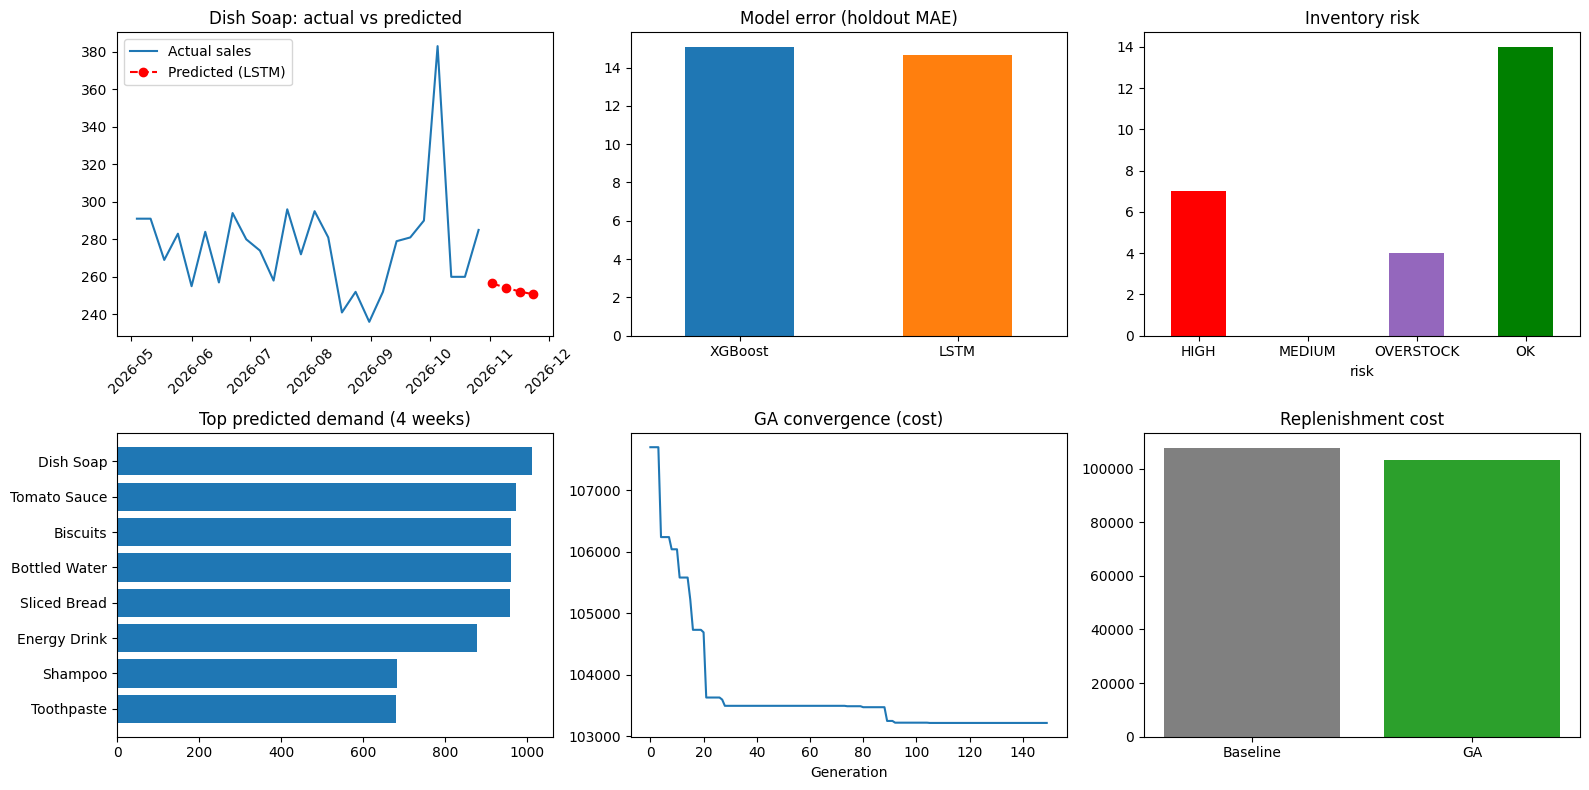

In [19]:
#Step 15
# Dashboard
top = recs.sort_values("demand_4w", ascending=False).iloc[0]
pid = top.product_id
fig, ax = plt.subplots(2, 3, figsize=(16, 8))

ax[0, 0].plot(weeks[-26:], series[pid][-26:], label="Actual sales")
ax[0, 0].plot(future, fc[pid], "r--o", label=f"Predicted ({best[pid]})")
ax[0, 0].set_title(f"{top['name']}: actual vs predicted")
ax[0, 0].legend(); ax[0, 0].tick_params(axis="x", rotation=45)

model_metrics["MAE"].plot.bar(ax=ax[0, 1], color=["tab:blue", "tab:orange"])
ax[0, 1].set_title("Model error (holdout MAE)"); ax[0, 1].tick_params(axis="x", rotation=0)

recs.risk.value_counts().reindex(["HIGH", "MEDIUM", "OVERSTOCK", "OK"]).fillna(0).plot.bar(
    ax=ax[0, 2], color=["red", "orange", "tab:purple", "green"])
ax[0, 2].set_title("Inventory risk"); ax[0, 2].tick_params(axis="x", rotation=0)

t8 = recs.sort_values("demand_4w").tail(8)
ax[1, 0].barh(t8["name"], t8.demand_4w)
ax[1, 0].set_title("Top predicted demand (4 weeks)")

ax[1, 1].plot(ga_hist)
ax[1, 1].set_title("GA convergence (cost)"); ax[1, 1].set_xlabel("Generation")

ax[1, 2].bar(["Baseline", "GA"], [base_cost, ga_cost], color=["gray", "tab:green"])
ax[1, 2].set_title("Replenishment cost")

plt.tight_layout()
plt.show()

In [20]:
#Step 16
# Responsible AI summary
print("DemandIQ transparency summary")
print("- Forecast models   : XGBoost and LSTM, best one chosen per product on holdout error")
print("- Models used       :", best.value_counts().to_dict())
print("- Holdout metrics   :")
display(model_metrics)
print("- Predictions are labelled PREDICTION and are never mixed with actual sales")
print("- Every recommendation has reasons (see explain) and needs human approval")
print("- Status counts     :", recs.status.value_counts().to_dict())

DemandIQ transparency summary
- Forecast models   : XGBoost and LSTM, best one chosen per product on holdout error
- Models used       : {'LSTM': 14, 'XGBoost': 11}
- Holdout metrics   :


,MAE,RMSE,MAPE %
XGBoost,15.09,21.76,10.72
LSTM,14.65,22.13,10.37


- Predictions are labelled PREDICTION and are never mixed with actual sales
- Every recommendation has reasons (see explain) and needs human approval
- Status counts     : {'NO ACTION': 19, 'APPROVED': 6}


In [21]:
#Step 17
recs.drop(columns=["reasons"]).to_csv("demandiq_recommendations.csv", index=False)
files.download("demandiq_recommendations.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>